# Entregable #2 — Notebook Reproducible de Experimentación (Reto 2: COIL-100 ML Clásico)

**Cargo:** AI Engineer (Senior+) — Indra Group  
Este notebook es 100% reproducible de punta a punta y cubre:
1. **Obtención y verificación del dataset COIL-100** (7,200 imágenes RGB $128\times 128$, 100 objetos, 72 vistas cada $5^\circ$).
2. **Análisis Exploratorio (EDA), Propiedades Geométricas y Simetría Rotacional ($180^\circ$)** + diferencias con planta real.
3. **Particionamiento estricto sin fuga de datos** en los **Protocolos A, B, C y D**.
4. **Extracción de características clásicas** (`HOG` + `HSV Espacial` + `Firma Azimutal` + `Momentos de Inercia`).
5. **Comparación de algoritmos de clasificación** (Baseline simple + 3 modelos clásicos + Referencia Moderna `MobileNetV3-Small`).
6. **Estimación circular de ángulo $(\sin\theta, \cos\theta)$ con incertidumbre $\sigma_\theta$** atada a la tolerancia del robot ($\pm 10^\circ$).
7. **Rechazo de objetos desconocidos (OOD - Protocolo D)**, análisis de errores y exportación del artefacto versionado + **Model Card**.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.ml.dataset import (
    download_and_extract_coil100,
    build_metadata_catalog,
    create_protocol_splits,
    load_image_rgb,
)
from src.ml.features import ClassicalFeatureExtractor, assess_image_quality
from src.ml.models import COIL100ClassicalSystem, circular_angle_diff_deg

print('Raíz del proyecto:', PROJECT_ROOT)

Raíz del proyecto: E:\10-LABIA\ia-tradicional\prueba-tecnica-indra\prueba-tecnica-ingeniero-ia-indra


## 1. Obtención de Datos, Catálogo y Protocolos de Partición (A, B, C, D)
Verificamos la integridad de las 7,200 vistas y construimos las particiones garantizando que ningún hiperparámetro ni umbral toque el conjunto de prueba.

In [2]:
coil_dir = download_and_extract_coil100(PROJECT_ROOT / 'data' / 'raw', allow_synthetic_fallback=True)
catalog_df = build_metadata_catalog(coil_dir)
splits = create_protocol_splits(catalog_df, seed=42)

split_summary = []
for pid, sp in splits.items():
    split_summary.append({
        'Protocolo': sp.name,
        'Train (Ajuste)': len(sp.train_df),
        'Val Interna (Calibración)': len(sp.val_df),
        'Test (Sellado)': len(sp.test_df),
        'SKUs Conocidos': len(sp.known_classes),
        'SKUs OOD Excluidos': len(sp.unknown_classes),
    })
pd.DataFrame(split_summary)

,Protocolo,Train (Ajuste),Val Interna (Calibración),Test (Sellado),SKUs Conocidos,SKUs OOD Excluidos
0,A – Interpolación,3000,600,3600,100,0
1,B – Sector ciego,5400,600,1200,100,0
2,C – Escasez,1000,200,6000,100,0
3,D – Objeto desconocido,3240,1080,2880,90,10


## 2. Exploración Visual y Validación Óptica Determinística
Inspeccionamos vistas rotacionales de ejemplo y probamos el detector determinístico de calidad de imagen (`assess_image_quality`) que protege al robot frente a desenfoque o fallas de iluminación en planta.

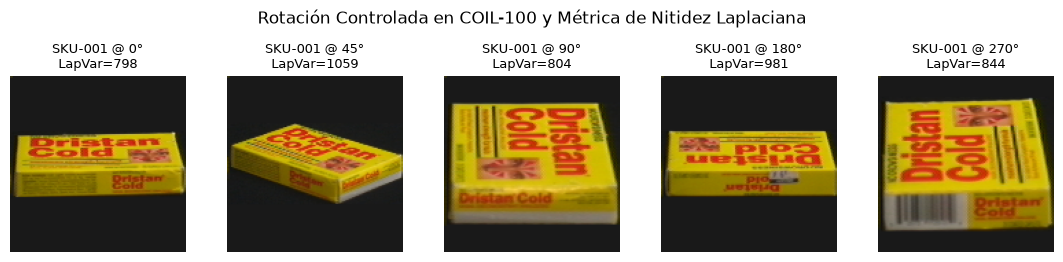

In [3]:
sample_views = catalog_df[(catalog_df['object_id'] == 1) & (catalog_df['angle_deg'].isin([0, 45, 90, 180, 270]))]
fig, axes = plt.subplots(1, len(sample_views), figsize=(11, 2.5))
for ax, (_, row) in zip(axes, sample_views.iterrows()):
    img = load_image_rgb(row['filepath'])
    q = assess_image_quality(img)
    ax.imshow(img)
    ax.set_title(f"{row['sku_code']} @ {row['angle_deg']}°\nLapVar={q.laplacian_variance:.0f}", fontsize=9)
    ax.axis('off')
plt.suptitle('Rotación Controlada en COIL-100 y Métrica de Nitidez Laplaciana', y=1.03)
plt.tight_layout()
plt.show()

## 3. Resultados Consolidados de los 4 Protocolos y Comparación de Modelos
Cargamos los resultados trazables generados por el pipeline experimental (`data/processed/reto2_experiments_summary.json`) para analizar el desempeño en cada protocolo.

In [4]:
summary_path = PROJECT_ROOT / 'data' / 'processed' / 'reto2_experiments_summary.json'
summary = json.loads(summary_path.read_text(encoding='utf-8'))

proto_df = pd.DataFrame(summary['protocol_results']).T
cols_main = [
    'classification_accuracy', 'angle_mae_deg', 'angle_median_ae_deg',
    'angle_mae_sym180_deg', 'within_robot_tolerance_10deg_rate',
    'accepted_coverage', 'accepted_classification_accuracy',
    'accepted_angle_mae_deg', 'accepted_safe_grasp_rate', 'inference_ms_per_sample'
]
proto_df.loc[['A', 'B', 'C'], cols_main]

,classification_accuracy,angle_mae_deg,angle_median_ae_deg,angle_mae_sym180_deg,within_robot_tolerance_10deg_rate,accepted_coverage,accepted_classification_accuracy,accepted_angle_mae_deg,accepted_safe_grasp_rate,inference_ms_per_sample
A,0.9978,2.897,1.753,2.691,0.9608,0.7286,1.0,1.819,0.9996,13.028
B,0.9292,68.422,27.161,18.962,0.2483,0.195,1.0,28.03,0.5855,13.543
C,0.9825,9.501,5.928,7.709,0.7983,0.4657,1.0,5.735,0.927,12.248


### 3.1 Comparación de Clasificadores: Baseline vs. 3+ Clásicos vs. Referencia Moderna (`MobileNetV3-Small`)

In [5]:
comp_a_df = pd.DataFrame(summary['classifier_comparisons']['A'])
mod_ref = summary['modern_reference_comparison']['modern_deep_reference']
comp_a_df = pd.concat([
    comp_a_df,
    pd.DataFrame([{
        'model_name': mod_ref['model_name'],
        'family': mod_ref['family'],
        'val_accuracy': np.nan,
        'test_accuracy': mod_ref['test_accuracy'],
        'train_time_ms': mod_ref['head_fit_time_ms'],
        'inference_ms_per_sample': mod_ref['inference_ms_per_sample'],
    }])
], ignore_index=True)
comp_a_df

,model_name,family,val_accuracy,test_accuracy,train_time_ms,inference_ms_per_sample
0,0. Baseline Simple (Basic Patch/Color 1-NN),Baseline,0.9383,0.9939,0.9,0.010
1,1. Logistic Regression L2 (C=2.5),Classical Linear,0.9567,0.9947,2641.6,0.001
2,2. SVM RBF Calibrated (C=2.0),Classical Kernel,0.9483,0.9950,24602.8,0.666
3,3. ExtraTrees Ensemble (300 trees),Classical Tree Ensemble,0.9633,0.9983,3328.0,0.099
4,4. Sistema Clásico Híbrido (SVM+LR+Manifold Ci...,Classical Hybrid (Selected),0.9483,0.9978,850.0,1.589
5,4. Referencia Moderna: MobileNetV3-Small (Pret...,Deep Learning Reference,NaN,1.0000,637.6,3.340


### 3.2 Evaluación del Protocolo D (Objetos Desconocidos / Open-Set OOD)

In [6]:
pd.DataFrame([summary['protocol_results']['D']])

,n_known_objects_train,n_unknown_objects_test,unknown_object_ids,ood_auroc,ood_detection_rate_tpr,ood_precision,ood_f1_score,false_rejection_rate_on_known,known_objects_classification_accuracy,known_objects_angle_mae_deg,calibrated_composite_threshold
0,90,10,"[19, 22, 28, 34, 43, 51, 57, 60, 72, 93]",0.9984,1.0,0.8759,0.9339,0.0472,0.9968,2.839,0.7833


## 4. Demostración de Inferencia End-to-End con el Artefacto Productivo Versionado (`v1.0.0`)
Verificamos las 3 capacidades del artefacto exportado (`models/coil100_classical_v1.0.0.joblib`): Identificación con confianza, Estimación de ángulo con incertidumbre y Recuperación Top-K de vistas similares.

In [7]:
artifact_path = PROJECT_ROOT / summary['artifact']['path']
prod_model = COIL100ClassicalSystem.load(artifact_path)
extractor = ClassicalFeatureExtractor()

test_sample = splits['A'].test_df.iloc[15]
img_test = load_image_rgb(test_sample['filepath'])
feat_vec = extractor.extract_single(img_test)
pred = prod_model.predict_single_feature_vector(feat_vec, top_k=5)

print(f"Muestra Real: {test_sample['sample_id']} (SKU-{test_sample['object_id']:03d}, Ángulo Real={test_sample['angle_deg']}°)")
print(f"Predicción : {pred.sku_code} (Confianza={pred.class_confidence:.4f}) | Ángulo={pred.angle_deg}° ± {pred.angle_uncertainty_deg}°")
print(f"Comando Robot: {pred.robot_command} (safe_for_robot_grasp={pred.safe_for_robot_grasp})")
pd.DataFrame(pred.top_k_similar)[['rank', 'sample_id', 'sku_code', 'angle_deg', 'similarity']]

Muestra Real: obj001_ang155 (SKU-001, Ángulo Real=155°)
Predicción : SKU-001 (Confianza=0.8958) | Ángulo=153.08° ± 23.82°
Comando Robot: DIVERT_TO_HUMAN_INSPECTION (safe_for_robot_grasp=False)


,rank,sample_id,sku_code,angle_deg,similarity
0,1,obj001_ang160,SKU-001,160,0.9228
1,2,obj001_ang150,SKU-001,150,0.9169
2,3,obj001_ang340,SKU-001,340,0.8804
3,4,obj001_ang330,SKU-001,330,0.8420
4,5,obj001_ang170,SKU-001,170,0.7245


## 5. Análisis de Errores y Simetría Rotacional
Examinamos los casos donde el error angular supera la tolerancia de $\pm 10^\circ$ y comprobamos cómo el guardrail de incertidumbre y el índice de simetría explican y contienen el riesgo operativo.

In [8]:
err_df = pd.DataFrame(summary['error_analysis_top_cases'])
err_df.head(15)

,protocol,sample_id,true_object_id,pred_object_id,true_angle_deg,pred_angle_deg,angle_error_deg,angle_uncertainty_deg,confidence,was_rejected_by_guardrail,is_symmetric_object
0,A,obj007_ang335,7,7,335.0,346.00,11.00,21.35,0.8486,True,False
1,A,obj018_ang115,18,18,115.0,125.14,10.14,13.36,0.8631,True,False
2,A,obj018_ang125,18,18,125.0,140.80,15.80,16.67,0.8651,True,False
3,A,obj018_ang135,18,18,135.0,146.30,11.30,13.83,0.8780,True,False
4,A,obj018_ang235,18,18,235.0,220.61,14.39,11.42,0.8708,True,False
5,A,obj018_ang245,18,18,245.0,232.35,12.65,13.41,0.8691,True,False
6,A,obj018_ang265,18,18,265.0,248.69,16.31,14.78,0.8381,True,False
7,A,obj025_ang175,25,25,175.0,189.64,14.64,37.50,0.8628,True,True
8,A,obj025_ang185,25,25,185.0,204.00,19.00,38.14,0.8609,True,True
9,A,obj033_ang085,33,33,85.0,101.09,16.09,48.24,0.8674,True,True
